# Top 10s over time

How my ten most played artists, albums, and songs built up their play counts, one line each and one chart for each.

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from matplotlib.transforms import blended_transform_factory

from viz import SERIES_COLORS, SURFACE, INK, INK_SECONDARY, MUTED, GRID, BASELINE, add_title, save_figure

DATA_DIR = '.' if os.path.exists('scrobbles.parquet') else 'sample_data'  # falls back to the bundled sample
print(f'data: {DATA_DIR}')

df = pd.read_parquet(f'{DATA_DIR}/scrobbles.parquet')
print(df.shape)

data: .
(34009, 5)


## Items and days

Albums and songs are identified by artist plus title, since titles repeat across artists. Scrobbles with no album are left out of the album ranking. Each scrobble is assigned to the day it was played in local time.

In [7]:
df['day'] = df['played_at'].dt.tz_localize(None).dt.normalize()
df['album_key'] = (df['album'] + ' (' + df['artist'] + ')').where(df['album'] != '')  # no album, no key
df['track_key'] = df['track'] + ' (' + df['artist'] + ')'

KINDS = {'Artists': 'artist', 'Albums': 'album_key', 'Songs': 'track_key'}  # panel title and the column it ranks
days = pd.date_range(df['day'].min(), df['day'].max())  # every day, so quiet days stay on the line

## Running totals

Plays are counted per day for the ten most played items, then summed over time. Every item starts at zero, so a line that stays flat and then climbs is something I found later.

In [8]:
TOP_N = 10


def running_totals(column, n=TOP_N):
    '''Running total of plays for the n most played items, one column each, most played first.'''
    top = df[column].value_counts().head(n).index
    daily = df[df[column].isin(top)].groupby(['day', column]).size().unstack(fill_value=0)
    return daily.reindex(days, fill_value=0)[top].cumsum()


running_totals('artist').tail(1).T

,2026-11-12
artist,
The Beatles,836
The Strokes,705
Daft Punk,599
Radiohead,527
TV Girl,425
Lana Del Rey,407
MF DOOM,366
Phantogram,339
Arctic Monkeys,338


## The figure

Eight colors is about as many as stay easy to tell apart on a dark background, so the ninth and tenth lines reuse the first two as dashes. Each line is named at its right end. The names are spread apart when two lines finish close together, with a short connector back to the line.

In [9]:
def spread(ends, gap, low, high):
    '''Label heights for lines that finish at `ends`: no two closer than `gap`, all between `low` and `high`.'''
    order = np.argsort(ends)
    heights = np.asarray(ends, dtype=float)[order]
    for _ in range(200):  # nudge neighbors that are too close, each by half of the shortfall, until they settle
        shortfall = gap - np.diff(heights)
        if shortfall.max() <= 1e-9:
            break
        for i in np.flatnonzero(shortfall > 0):
            heights[i] -= shortfall[i] / 2
            heights[i + 1] += shortfall[i] / 2
        heights = np.clip(heights, low, high)
    result = np.empty(len(heights))
    result[order] = heights
    return result


def short_label(text, limit=38):
    return text if len(text) <= limit else text[:limit - 1].rstrip() + '\u2026'


def style_axes(ax):
    '''Hairline grid on the y axis and no frame except the baseline.'''
    ax.set_facecolor(SURFACE)
    ax.grid(axis='y', color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ('top', 'right', 'left'):
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(BASELINE)
    ax.tick_params(length=0, labelsize=9, labelcolor=MUTED)

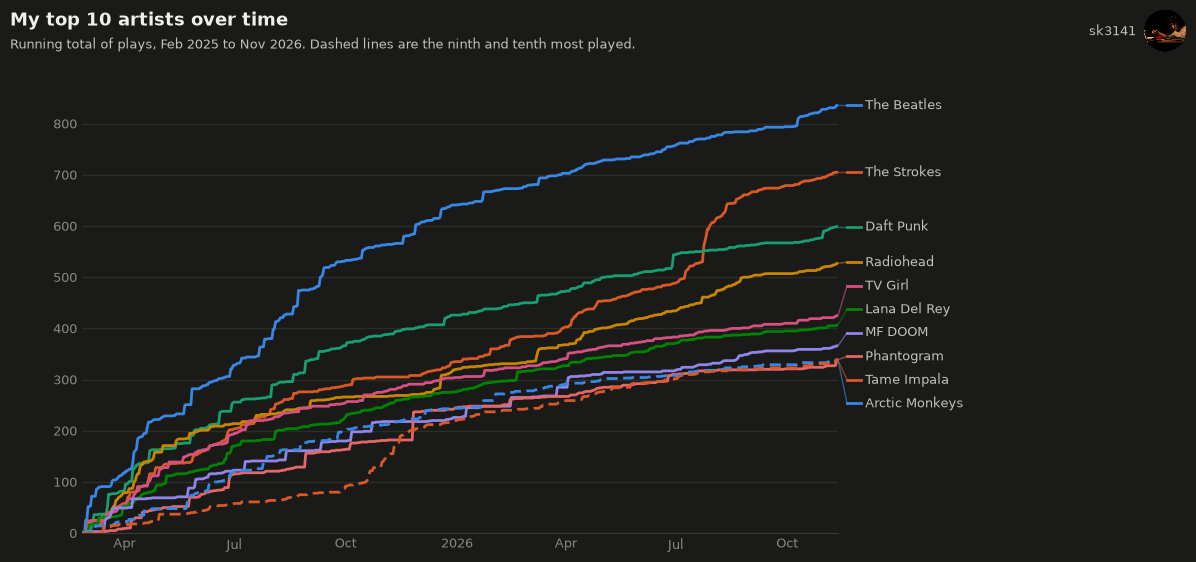

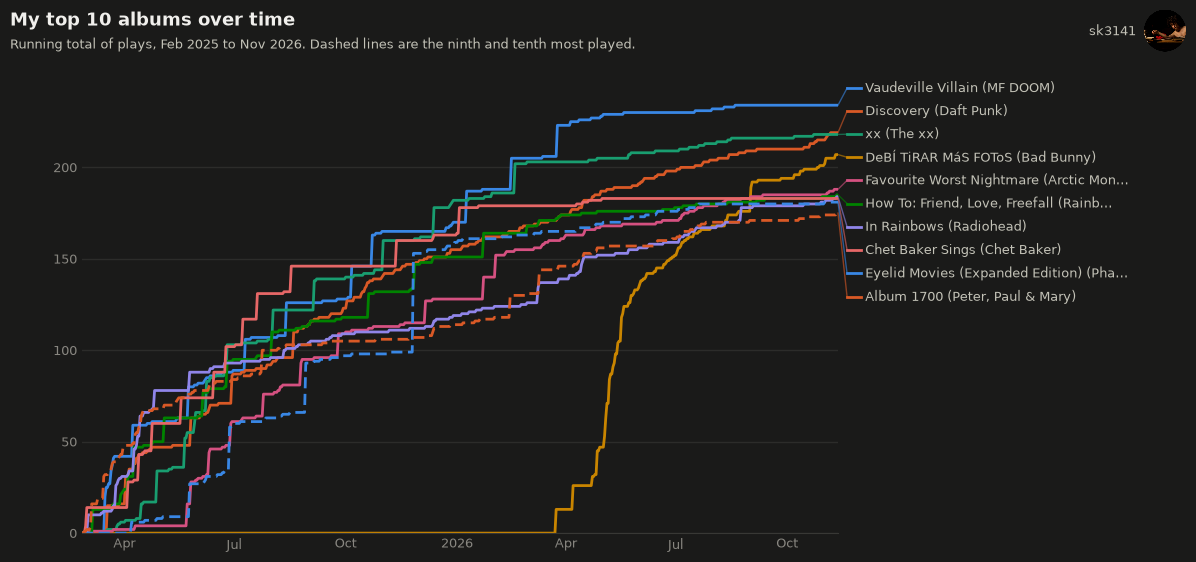

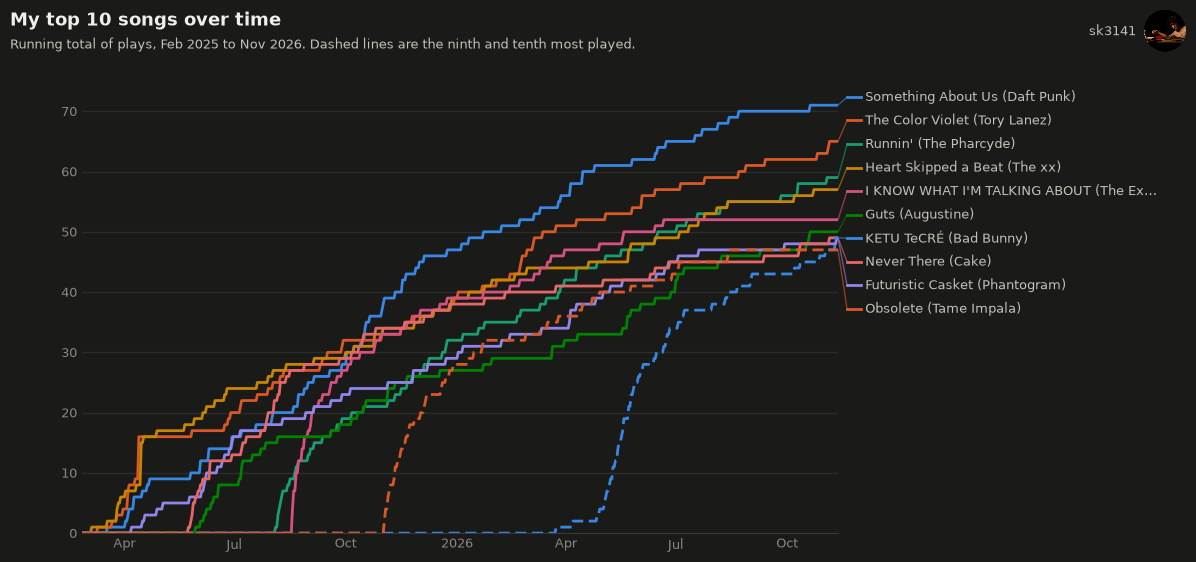

In [10]:
def plot_top_over_time(title, column, save=False):
    '''One figure: a line for each of the top ten items in `column`.'''
    height = 5.8
    fig, ax = plt.subplots(figsize=(12, height), facecolor=SURFACE)

    totals = running_totals(column)
    top = totals.max().max()
    edge = blended_transform_factory(ax.transAxes, ax.transData)  # x as a fraction of the axes, y in data units
    label_y = spread(totals.iloc[-1].to_numpy(), gap=top * 0.055, low=0, high=top * 1.04)

    for rank, name in enumerate(totals.columns):
        color = SERIES_COLORS[rank % len(SERIES_COLORS)]
        style = '-' if rank < len(SERIES_COLORS) else (0, (4, 2))  # dashes for the lines past the eighth color
        end_y = totals[name].iloc[-1]
        ax.plot(totals.index, totals[name], color=color, linewidth=2, linestyle=style)
        ax.plot([1.0, 1.012], [end_y, label_y[rank]], transform=edge, color=color, linewidth=1, alpha=0.6, clip_on=False)
        ax.plot([1.012, 1.03], [label_y[rank]] * 2, transform=edge, color=color, linewidth=2, clip_on=False)
        ax.text(1.036, label_y[rank], short_label(name), transform=edge, va='center', ha='left',
                fontsize=9, color=INK_SECONDARY)

    ax.set_xlim(days[0], days[-1])
    ax.set_ylim(0, top * 1.06)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
    locator = mdates.AutoDateLocator(minticks=5, maxticks=9)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    style_axes(ax)

    add_title(fig, f'My top {TOP_N} {title.lower()} over time',
              f'Running total of plays, {days[0]:%b %Y} to {days[-1]:%b %Y}. Dashed lines are the ninth and tenth most played.', height)
    fig.subplots_adjust(left=0.07, right=0.70, top=1 - 0.8 / height, bottom=0.08)
    if save:
        save_figure(fig, f'top_{title.lower()}_over_time')
    plt.show()


for title, column in KINDS.items():
    plot_top_over_time(title, column, save=True)